In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

In [27]:
df = pd.read_csv(r"C:\Users\USER\Downloads\StudentsPerformance.csv")

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [28]:
#Random Sampling

df.sample(n=10)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
430,male,group C,associate's degree,free/reduced,none,64,66,59
379,male,group A,bachelor's degree,standard,none,66,64,62
801,male,group C,some high school,standard,completed,76,80,73
261,male,group C,some college,standard,completed,79,79,78
900,male,group D,master's degree,standard,none,85,84,89
791,female,group D,some college,free/reduced,none,60,66,70
5,female,group B,associate's degree,standard,none,71,83,78
520,male,group D,some college,standard,none,71,49,52
8,male,group D,high school,free/reduced,completed,64,64,67
369,female,group D,some high school,standard,none,73,84,85


In [29]:
#Random state is just to save a particular randomization

df.sample(n=10, random_state = 5)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
544,female,group D,master's degree,standard,none,64,63,66
515,female,group C,some high school,standard,completed,76,87,85
193,male,group D,some college,standard,completed,77,62,62
11,male,group D,associate's degree,standard,none,40,52,43
279,male,group B,bachelor's degree,free/reduced,none,73,56,57
653,female,group A,associate's degree,standard,completed,65,70,74
643,female,group E,high school,standard,completed,74,79,80
763,female,group B,high school,standard,none,62,62,63
198,female,group B,some college,free/reduced,none,45,53,55
721,male,group D,some high school,free/reduced,completed,55,59,59


In [30]:
#Systematic Sampling
systematic_sample = df.iloc[: : 10] #to select every nth element

systematic_sample

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
10,male,group C,associate's degree,standard,none,58,54,52
20,male,group D,high school,standard,none,66,69,63
30,female,group D,some college,standard,none,69,74,74
40,male,group C,associate's degree,free/reduced,none,55,61,54
...,...,...,...,...,...,...,...,...
950,male,group E,high school,standard,none,94,73,71
960,female,group A,some college,standard,none,56,58,64
970,female,group D,bachelor's degree,standard,none,89,100,100
980,female,group B,high school,free/reduced,none,8,24,23


In [31]:
#stratified sampling
stratified_sample = df.groupby("gender", group_keys=False).apply(lambda x:x.sample(5,random_state=1))

stratified_sample

C:\Users\USER\AppData\Local\Temp\ipykernel_3580\3324965997.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  stratified_sample = df.groupby("gender", group_keys=False).apply(lambda x:x.sample(5,random_state=1))


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
947,female,group D,some college,free/reduced,none,49,58,60
552,female,group B,associate's degree,standard,none,40,48,50
816,female,group A,bachelor's degree,standard,none,45,59,64
620,female,group C,high school,free/reduced,none,35,61,54
517,female,group E,some college,standard,completed,66,74,73
62,male,group A,associate's degree,free/reduced,none,62,61,55
482,male,group C,some college,free/reduced,none,68,68,61
358,male,group D,some college,free/reduced,none,59,62,61
218,male,group B,high school,free/reduced,none,66,77,70
184,male,group C,some high school,free/reduced,completed,45,52,49


In [32]:
df["math score"].mean()

np.float64(66.089)

In [33]:
df["math score"].median()

66.0

In [34]:
df["math score"].mode()

0    65
Name: math score, dtype: int64

In [35]:
df["lunch"].mode()

0    standard
Name: lunch, dtype: object

In [36]:
df["math score"].var()

229.91899799799847

In [37]:
df["math score"].std()

15.163080096009468

In [38]:
range_math_score =(df["math score"].max()) - (df["math score"].min())

range_math_score

100

In [39]:
df["math score"].describe()

count    1000.00000
mean       66.08900
std        15.16308
min         0.00000
25%        57.00000
50%        66.00000
75%        77.00000
max       100.00000
Name: math score, dtype: float64

## Shape Of Distribution(Skewness and Kurtosis)

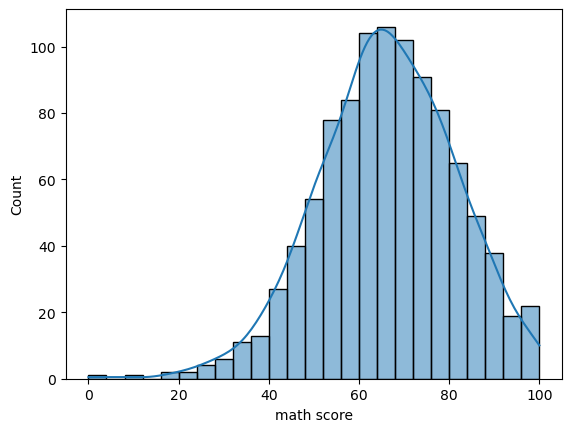

In [40]:
sns.histplot(df["math score"], kde =True)

plt.show()

In [41]:
math_skewness = skew(df["math score"])

math_skewness

np.float64(-0.278516571914075)

In [43]:
math_kurtosis = kurtosis(df["math score"], fisher=False)

math_kurtosis

np.float64(3.2675971546149785)

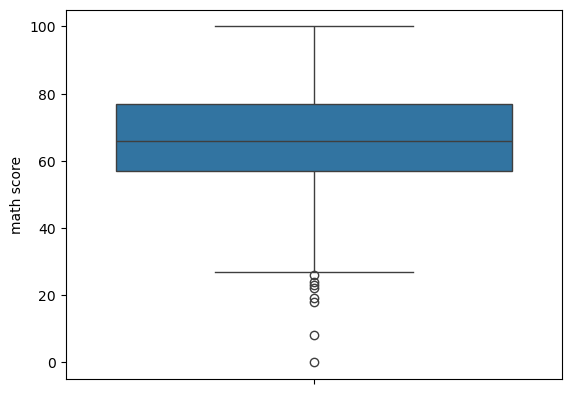

In [52]:
sns.boxplot(y = df["math score"])

plt.show()   #Ooutliers greatly affect mean and median is not always affected by outliers

In [45]:
Q1 = df["math score"].quantile(0.25)

Q1

np.float64(57.0)

In [46]:
Q3 = df["math score"].quantile(0.75)

Q3

np.float64(77.0)

In [47]:
IQR = Q3 - Q1

IQR

np.float64(20.0)

In [48]:
lower_whisker = Q1 - 1.5*IQR
upper_whisker = Q3 + 1.5*IQR

In [49]:
lower_whisker

np.float64(27.0)

In [50]:
upper_whisker

np.float64(107.0)

In [53]:
#Outliers are not strange data points they are just extreme points, so some times they are important

In [54]:
df[(df["math score"] < lower_whisker) | (df["math score"] > upper_whisker)]

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
17,female,group B,some high school,free/reduced,none,18,32,28
59,female,group C,some high school,free/reduced,none,0,17,10
145,female,group C,some college,free/reduced,none,22,39,33
338,female,group B,some high school,free/reduced,none,24,38,27
466,female,group D,associate's degree,free/reduced,none,26,31,38
787,female,group B,some college,standard,none,19,38,32
842,female,group B,high school,free/reduced,completed,23,44,36
980,female,group B,high school,free/reduced,none,8,24,23


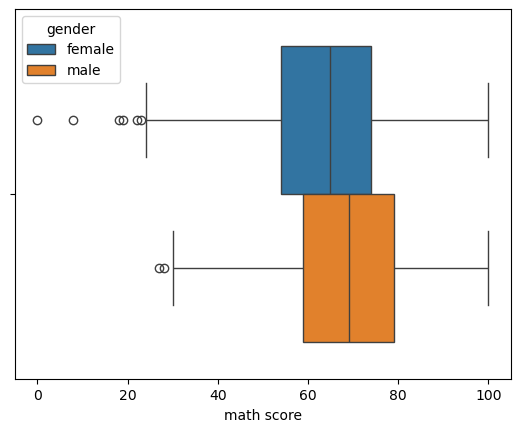

In [55]:
sns.boxplot(data = df, x = "math score", hue = "gender")

plt.show()

## CENTRAL LIMIT THEOREM

#### Used to assume our data is normally distributed

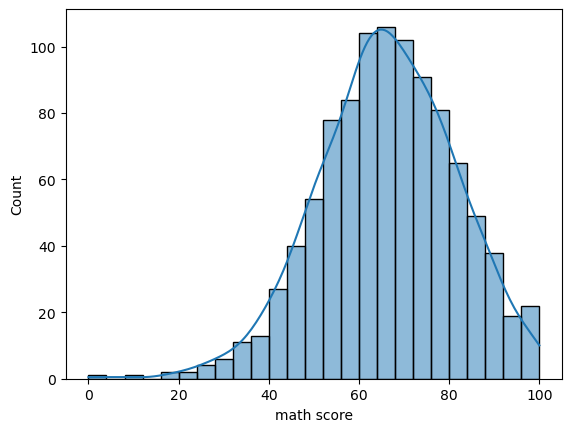

In [56]:
sns.histplot(df["math score"], kde = True)

plt.show()

In [65]:
sample_mean = []

for i in range (1000):
    sample = df["math score"].sample(n=30, replace = True)
    sample_mean.append(sample.mean())

In [66]:
sample_mean

[np.float64(65.83333333333333),
 np.float64(67.33333333333333),
 np.float64(67.56666666666666),
 np.float64(66.73333333333333),
 np.float64(64.6),
 np.float64(69.2),
 np.float64(64.06666666666666),
 np.float64(68.33333333333333),
 np.float64(65.46666666666667),
 np.float64(64.96666666666667),
 np.float64(66.66666666666667),
 np.float64(63.4),
 np.float64(63.833333333333336),
 np.float64(69.53333333333333),
 np.float64(66.7),
 np.float64(68.63333333333334),
 np.float64(70.76666666666667),
 np.float64(64.26666666666667),
 np.float64(69.06666666666666),
 np.float64(66.8),
 np.float64(59.46666666666667),
 np.float64(70.1),
 np.float64(64.7),
 np.float64(66.96666666666667),
 np.float64(65.36666666666666),
 np.float64(68.1),
 np.float64(67.1),
 np.float64(68.83333333333333),
 np.float64(69.3),
 np.float64(69.2),
 np.float64(68.76666666666667),
 np.float64(66.53333333333333),
 np.float64(65.56666666666666),
 np.float64(60.1),
 np.float64(65.2),
 np.float64(65.76666666666667),
 np.float64(67.8

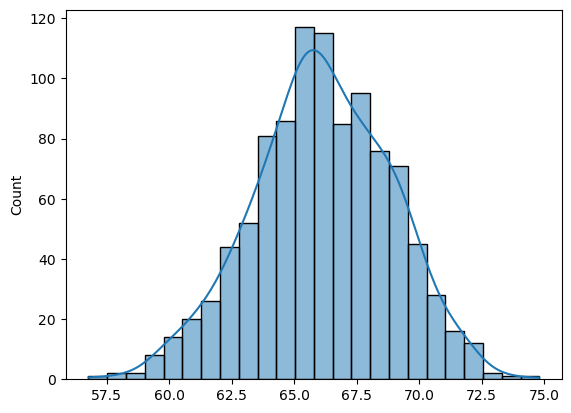

In [67]:
sns.histplot(sample_mean, kde = True)

plt.show()

## CORRELETION

It measures the strength and direction of a linear relationship. To calc. the linearity between two variables

Most times it ranges between -1 and 1 and you can only measure correlation using numerical variables

- 1 is perfect positive correlation
- 0 is no correlation
- -1 is perfect negative correlation

In [68]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [69]:
correlation_matrix = df[["math score", "reading score", "writing score"]].corr()

correlation_matrix

,math score,reading score,writing score
math score,1.000000,0.817580,0.802642
reading score,0.817580,1.000000,0.954598
writing score,0.802642,0.954598,1.000000


**Note that correlation is not causation**

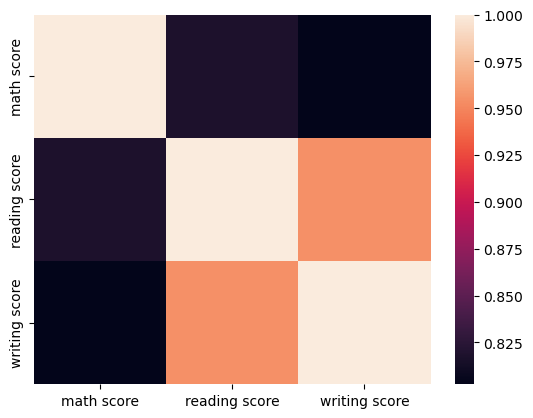

In [70]:
#We display correlation on a heat map

sns.heatmap(correlation_matrix)

plt.show()

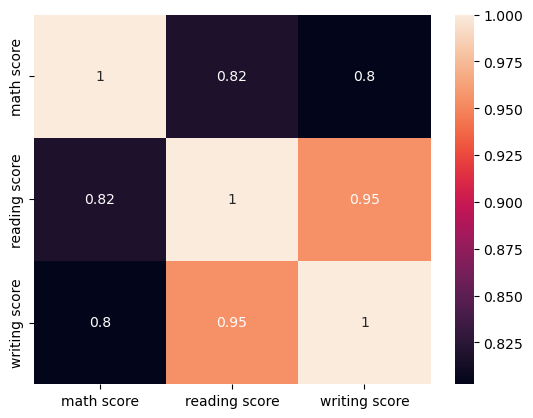

In [71]:
sns.heatmap(correlation_matrix, annot = True)

plt.show()

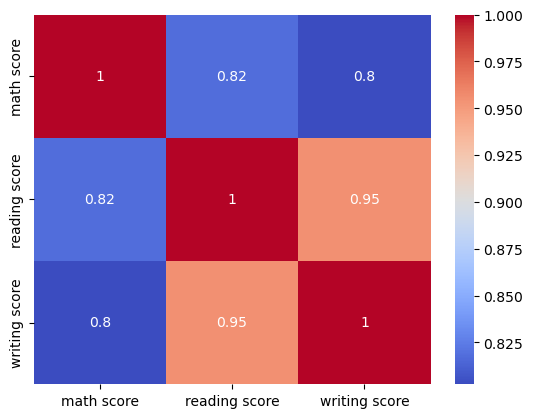

In [72]:
sns.heatmap(correlation_matrix, annot = True, cmap = "coolwarm")

plt.show()

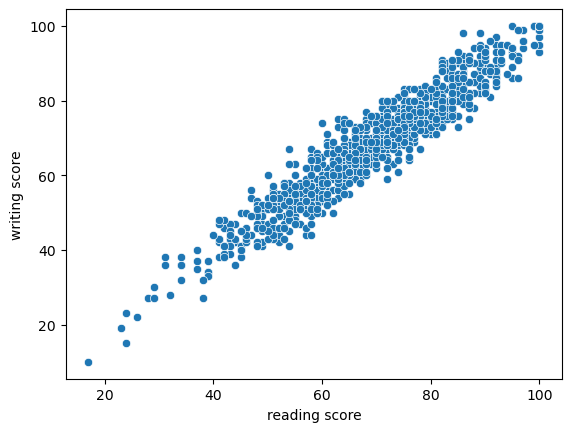

In [75]:
sns.scatterplot(x = df["reading score"], y = df["writing score"])

plt.show()

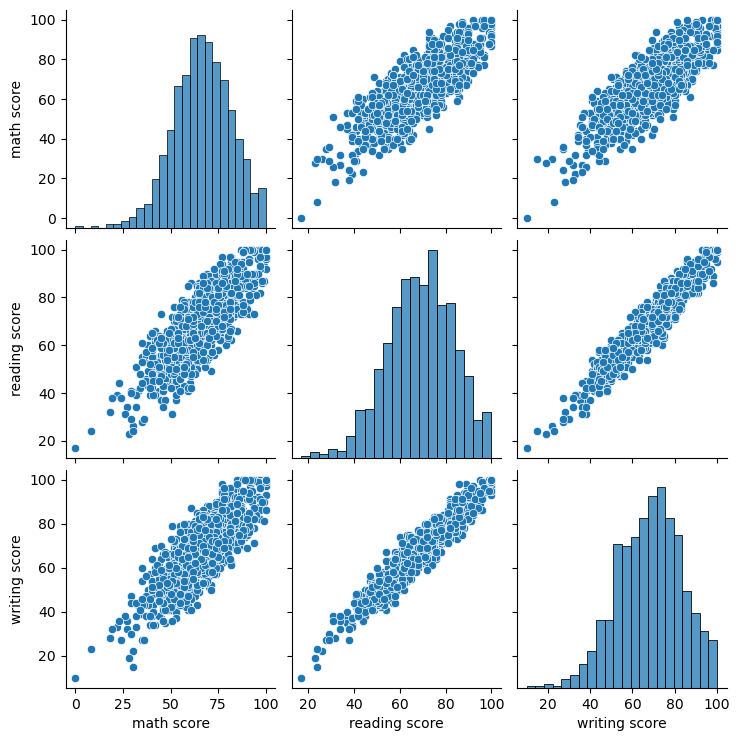

In [76]:
sns.pairplot(df[["math score", "reading score", "writing score"]])

plt.show()

## PROBABILITY

This is the likelyhood or chance of an event occuring. It ranges from 0 (impossible) to 1 (certain)

In [79]:
#Experimental Probability

#What is the probability that a student scored above 90 in maths?

prob_math_above_90 = len(df[df["math score"] > 90]) / len(df)

prob_math_above_90
#Total number of possible outcomes  / Total sample space

0.05

In [80]:
#Conditional Probability

#What is the probability a student passed maths, given that they completed the test preparation course

completed_preparation_course = df[df["test preparation course"] == "completed"]

completed_preparation_course

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
1,female,group C,some college,standard,completed,69,90,88
6,female,group B,some college,standard,completed,88,95,92
8,male,group D,high school,free/reduced,completed,64,64,67
13,male,group A,some college,standard,completed,78,72,70
18,male,group C,master's degree,free/reduced,completed,46,42,46
...,...,...,...,...,...,...,...,...
990,male,group E,high school,free/reduced,completed,86,81,75
991,female,group B,some high school,standard,completed,65,82,78
995,female,group E,master's degree,standard,completed,88,99,95
997,female,group C,high school,free/reduced,completed,59,71,65


In [81]:
prob_pass_math = len(completed_preparation_course[completed_preparation_course["math score"] >= 50]) / len(completed_preparation_course)

prob_pass_math

0.9217877094972067

In [82]:
#Joint Probality events are independent

#What is the probability a student is female and scored above 80 in reading?

joint_prob = len(df[(df["gender"] == "female") & (df["reading score"] > 80)]) / len(df)

joint_prob

0.159

## Confidence Interval, to infer the true mean

This is a range of values that is likely to contain the population parameter(like mean) based on a sample

In [83]:
sample = df["math score"].sample(n=50, random_state = 42)

mean = sample.mean()
std = sample.std()
n = len(sample)

In [85]:
#To calculate for "z" you get it from scipy

import scipy.stats as stats

confidence = 0.95   #(95%)

z = stats.norm.ppf((1 + confidence)/2)

z

np.float64(1.959963984540054)

In [86]:
#Google the confidence interval formula and use it

lower = mean - (z * (std/np.sqrt(n)))

In [87]:
upper = mean + (z * (std/np.sqrt(n)))

In [88]:
lower

np.float64(57.378568218583425)

In [89]:
upper

np.float64(67.98143178141657)

## Our Inference, remember our confidence is 95%

We are 95% confident that the population/true mean of the math score lies between 57.38 and 67.98

In [90]:
df["math score"].mean()

np.float64(66.089)